In [1]:
# import sys, importlib
# # Remove all cached hgctsvg modules
# to_del = [k for k in sys.modules if 'hgctsvg' in k]
# for k in to_del: del sys.modules[k]
# sys.path.insert(0, '/workspace/HGCTSVG/hgctsvg/src')
# import hgctsvg.pipeline.evaluation as ev
# import inspect
# src = inspect.getsource(ev.ClusterEvaluation.compute_CT_baseline_scores)
# print('RUNNING VERSION - first line of function:')
# print(src.split('\n')[1])
# print('File:', ev.__file__)

In [2]:
# compute silhouette score of ST
# compute ss of ct-SVG
    # average ss

# average ss of ST and ct-SVG on all runs

# Moran's I of all SVGs in ST-orig
# Moran's I of all ct-SVGs in ST-decomp

# compute jaccard of ST

# union all ct-SVG for each cell type
    # compute jaccard

# Average Moran's I of all genes
# Average Moran's I on all runs
# Average jaccard score on all runs

import pandas as pd
import scanpy as sc
import torch

from sklearn.metrics import silhouette_score, silhouette_samples

from pathlib import Path

from hgctsvg.preprocessing import common

from hgctsvg.metadata import ProjectMetadata
from hgctsvg.utils import (
    load_ct_spatial_data, 
    load_aggr_st_data
)

from hgctsvg.pipeline.evaluation import ClusterEvaluation

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3


In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / "Human Kidney Cancer Interface"

In [4]:
project_metadata = ProjectMetadata("hgctsvg_project_files/Human Kidney Cancer Interface")


In [5]:
cluster_eval = ClusterEvaluation()

In [6]:
st_baseline_scores = cluster_eval.compute_ST_baseline_scores()

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/pipeline/evaluation.py:178: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  adata_st.X = adata_st.X.todense()


In [7]:
st_baseline_scores

{'silhouette_pca': 0.10560193657875061,
 'silhouette_spatial': 0.14119887818881968}

In [8]:
ct_baseline_scores, mean_ct_baseline_scores = cluster_eval.compute_CT_baseline_scores(n_jobs=1)

In [9]:
ct_baseline_scores

{np.str_('B-cell'): {'silhouette_pca': 0.020065685734152794,
  'silhouette_spatial': -0.013486858785001648},
 np.str_('EC'): {'silhouette_pca': 0.018586624413728714,
  'silhouette_spatial': -0.4289956353828478},
 np.str_('Epi_PT'): {'silhouette_pca': 0.07040932774543762,
  'silhouette_spatial': 0.09062537417646392},
 np.str_('Epi_non-PT'): {'silhouette_pca': 0.17606273293495178,
  'silhouette_spatial': -0.27694852053665114},
 np.str_('Fibro'): {'silhouette_pca': 0.11723729968070984,
  'silhouette_spatial': -0.19029695719674097},
 np.str_('Mast'): {'silhouette_pca': 0.07516203075647354,
  'silhouette_spatial': -0.05159666308115345},
 np.str_('Myeloid'): {'silhouette_pca': -0.02800367772579193,
  'silhouette_spatial': -0.4711153882370508},
 np.str_('NK'): {'silhouette_pca': 0.03882249817252159,
  'silhouette_spatial': 0.07606070658364494},
 np.str_('Plasma'): {'silhouette_pca': 0.14737705886363983,
  'silhouette_spatial': 0.1195749968436426},
 np.str_('RCC'): {'silhouette_pca': 0.0666887

In [10]:
mean_ct_baseline_scores

{'silhouette_pca': np.float64(0.061474412912502885),
 'silhouette_spatial': np.float64(-0.15636017555980505)}

In [11]:
st_embedding_summary, st_embedding_run_scores = cluster_eval.compute_ST_embedding_scores()

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/pipeline/evaluation.py:210: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  adata_st.X = adata_st.X.todense()
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/

In [12]:
st_embedding_summary

{'silhouette_emb': {'mean': np.float64(0.12969962880015373),
  'std': np.float64(0.01026278798622259)},
 'silhouette_expr': {'mean': np.float64(0.008601707185152917),
  'std': np.float64(0.009805091323009617)},
 'silhouette_spatial': {'mean': np.float64(0.0928352145111037),
  'std': np.float64(0.031170113880443488)}}

In [13]:
st_embedding_run_scores

[{'silhouette_emb': 0.14177332818508148,
  'silhouette_expr': 0.02201729640364647,
  'silhouette_spatial': 0.1460413531549931},
 {'silhouette_emb': 0.11650672554969788,
  'silhouette_expr': -0.006000177934765816,
  'silhouette_spatial': 0.06404834259292731},
 {'silhouette_emb': 0.11375104635953903,
  'silhouette_expr': -0.0005149258067831397,
  'silhouette_spatial': 0.05572400595583315},
 {'silhouette_emb': 0.13254311680793762,
  'silhouette_expr': 0.009541787207126617,
  'silhouette_spatial': 0.09489729160787723},
 {'silhouette_emb': 0.12301655113697052,
  'silhouette_expr': -0.0065549262799322605,
  'silhouette_spatial': 0.06942317396310183},
 {'silhouette_emb': 0.14722760021686554,
  'silhouette_expr': 0.0185740627348423,
  'silhouette_spatial': 0.14974876253214245},
 {'silhouette_emb': 0.13770358264446259,
  'silhouette_expr': 0.01586075685918331,
  'silhouette_spatial': 0.08151530745243958},
 {'silhouette_emb': 0.13380810618400574,
  'silhouette_expr': 0.004322060849517584,
  'sil

In [14]:
ct_embedding_summary, ct_embedding_run_scores = cluster_eval.compute_CT_embedding_scores(n_jobs=1)

In [15]:
ct_embedding_summary

[{np.str_('B-cell'): {'silhouette_emb': 0.27309417724609375,
   'silhouette_expr': -0.04483653977513313,
   'silhouette_spatial': -0.07863219316252584},
  np.str_('EC'): {'silhouette_emb': 0.16088856756687164,
   'silhouette_expr': -0.03846876323223114,
   'silhouette_spatial': -0.07397662039919055},
  np.str_('Epi_PT'): {'silhouette_emb': 0.2602420747280121,
   'silhouette_expr': -0.05316951498389244,
   'silhouette_spatial': 0.06904469887620474},
  np.str_('Epi_non-PT'): {'silhouette_emb': 0.21110397577285767,
   'silhouette_expr': -0.05430250242352486,
   'silhouette_spatial': -0.12433365111302212},
  np.str_('Fibro'): {'silhouette_emb': 0.21611842513084412,
   'silhouette_expr': 0.006196201778948307,
   'silhouette_spatial': 0.008411165400917587},
  np.str_('Mast'): {'silhouette_emb': 0.22593006491661072,
   'silhouette_expr': 0.012488794513046741,
   'silhouette_spatial': 0.02028159324903518},
  np.str_('Myeloid'): {'silhouette_emb': 0.1304197609424591,
   'silhouette_expr': -0.05

In [16]:
ct_embedding_run_scores

{'silhouette_emb': {'mean': np.float64(0.2391596504797538),
  'std': np.float64(0.0071071100715414896)},
 'silhouette_expr': {'mean': np.float64(-0.03737804177799262),
  'std': np.float64(0.00515616231031334)},
 'silhouette_spatial': {'mean': np.float64(0.04546933177555331),
  'std': np.float64(0.01190173431166152)}}

## Spotiphy iscRNA + MICA baseline

Run the following **once** in the `scMiner` environment before executing the cell below:

```bash
conda run --no-capture-output -n scMiner python ../scripts/run_scminer_clustering.py \
    --iscRNA  spotiphy_project_files/Human\ Kidney\ Cancer\ Interface/ST_decomposition.h5ad \
    --out_dir hgctsvg_project_files/Human\ Kidney\ Cancer\ Interface/scminer_clusters/
```

This produces per-CT cluster CSVs in `scminer_clusters/` which are then loaded below.

In [29]:
# import importlib
# import hgctsvg.pipeline.evaluation
# importlib.reload(hgctsvg.pipeline.evaluation)
# from hgctsvg.pipeline.evaluation import ClusterEvaluation
# cluster_eval = ClusterEvaluation()

In [36]:
scminer_cluster_dir = project_metadata.project_folder / "scminer_clusters"
ct_spotiphy_scores, mean_ct_spotiphy_scores = cluster_eval.compute_CT_spotiphy_scores(scminer_cluster_dir)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_cr

In [37]:
mean_ct_spotiphy_scores

{'silhouette_mica': np.float64(0.15499885535507327),
 'silhouette_spatial': np.float64(0.1054148124332372)}

## HGCTSVG vs scMINER: Homogeneity Analysis

In [40]:
from sklearn.metrics import homogeneity_score, completeness_score
import pandas as pd, numpy as np, re
from pathlib import Path

scminer_dir = project_metadata.project_folder / 'scminer_clusters'
ct_list = project_metadata.ct_list

results = []
for ct in ct_list:
    safe = re.sub(r'[^A-Za-z0-9_]', '_', ct)
    sm_csv  = scminer_dir / f'{safe}.csv'
    hg_csv  = project_metadata.eval_dir / 'run_0' / f'clusters_ct_{ct}.csv'
    if not sm_csv.exists() or not hg_csv.exists():
        continue

    sm = pd.read_csv(sm_csv, dtype={'cell_id': str}).set_index('cell_id')
    hg = pd.read_csv(hg_csv, index_col=0)
    hg.index = hg.index.astype(str)

    common = sm.index.intersection(hg.index)
    if len(common) < 2:
        continue

    sm_labels = sm.loc[common, 'cluster'].values
    hg_labels = hg.loc[common, 'domain'].values

    if len(np.unique(sm_labels)) < 2 or len(np.unique(hg_labels)) < 2:
        continue

    h = homogeneity_score(sm_labels, hg_labels)   # are HGCTSVG domains within scMINER regions?
    c = completeness_score(sm_labels, hg_labels)   # does each scMINER region map to one HGCTSVG domain?
    results.append({'ct': ct, 'n_sm': len(np.unique(sm_labels)),
                    'n_hg': len(np.unique(hg_labels)),
                    'homogeneity': h, 'completeness': c})

df_results = pd.DataFrame(results).set_index('ct')
print(df_results.round(3).to_string())
print(f'\nMean homogeneity:  {df_results["homogeneity"].mean():.3f}')
print(f'Mean completeness: {df_results["completeness"].mean():.3f}')

            n_sm  n_hg  homogeneity  completeness
ct                                               
B-cell         2     8        0.401         0.130
EC             8    24        0.521         0.321
Epi_PT         2     6        0.454         0.185
Epi_non-PT    10    34        0.477         0.299
Fibro          7    12        0.409         0.330
Mast           2     6        0.454         0.179
Myeloid        7    23        0.297         0.188
NK             2     4        0.551         0.282
RCC            8    37        0.513         0.285
T-cell         4     9        0.286         0.178
pDC            2     4        0.162         0.082

Mean homogeneity:  0.411
Mean completeness: 0.224


## Spatial Awareness Results

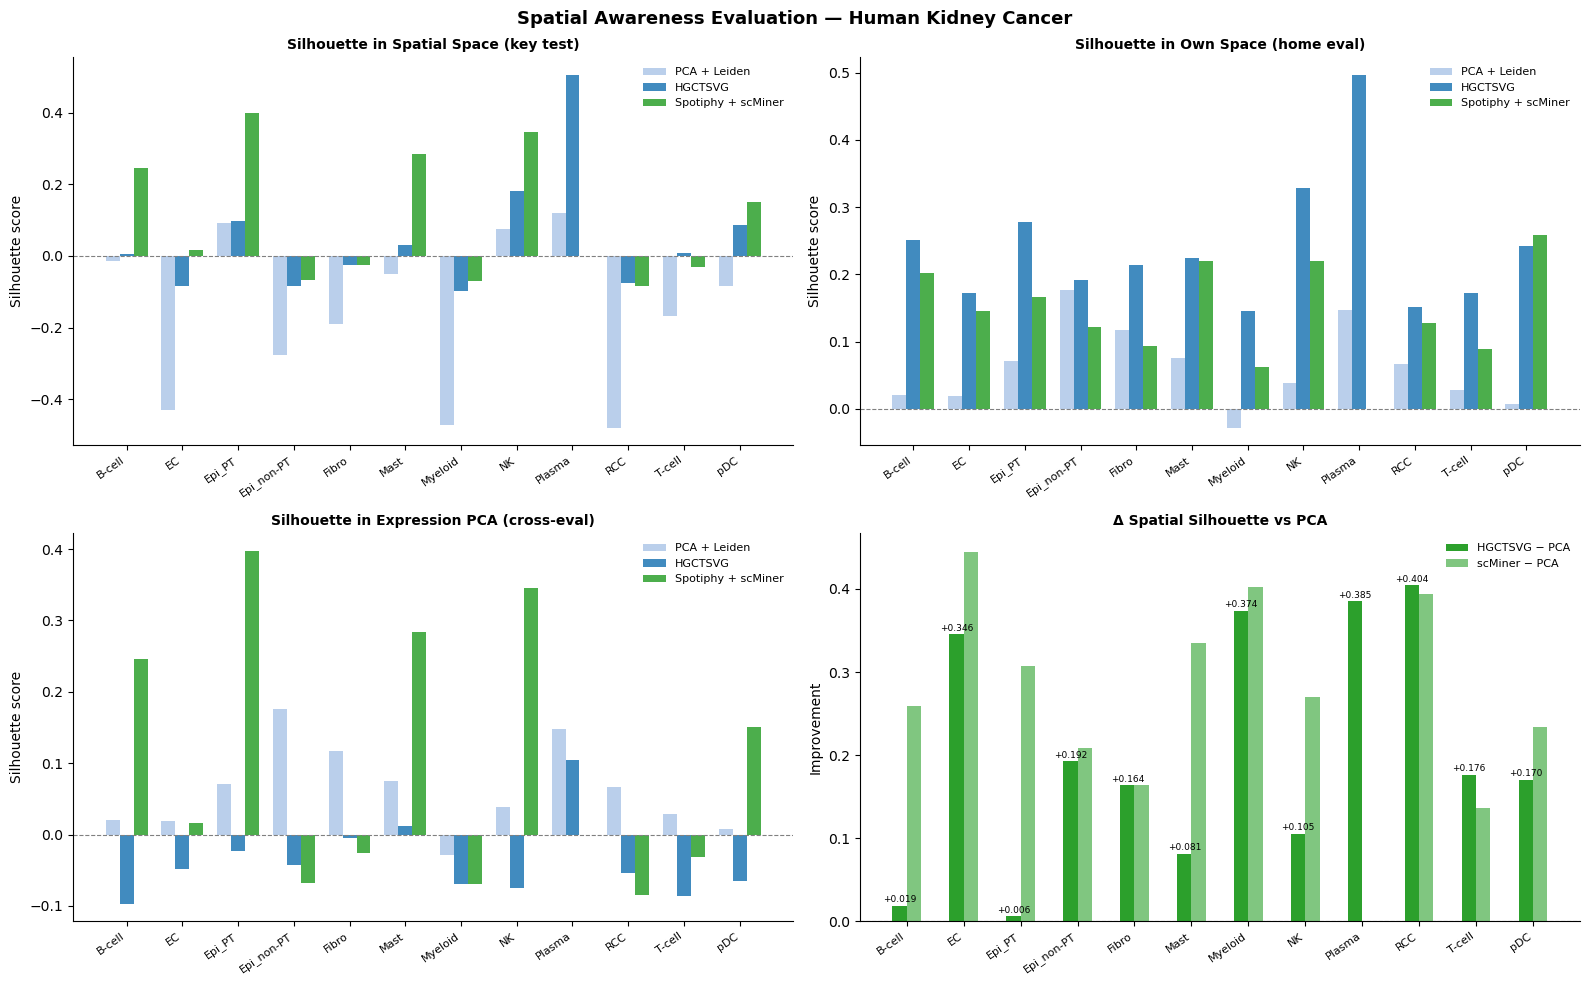

Mean Δ spatial (HGCTSVG − PCA): +0.2018
Mean Δ spatial (scMiner − PCA):  +0.2869


In [39]:
import matplotlib.pyplot as plt
import numpy as np

ct_list = project_metadata.ct_list

def _avg(run_list, ct, key):
    vals = [r[ct][key] for r in run_list if ct in r and key in r[ct]]
    return np.nanmean(vals) if vals else float('nan')

pca_spatial = [ct_baseline_scores.get(ct, {}).get('silhouette_spatial', float('nan')) for ct in ct_list]
pca_home    = [ct_baseline_scores.get(ct, {}).get('silhouette_pca',     float('nan')) for ct in ct_list]
hg_spatial  = [_avg(ct_embedding_summary, ct, 'silhouette_spatial') for ct in ct_list]
hg_home     = [_avg(ct_embedding_summary, ct, 'silhouette_emb')     for ct in ct_list]
hg_expr     = [_avg(ct_embedding_summary, ct, 'silhouette_expr')    for ct in ct_list]

# scMiner results (if available)
has_scminer = 'ct_spotiphy_scores' in dir() and ct_spotiphy_scores
sm_spatial  = [ct_spotiphy_scores.get(ct, {}).get('silhouette_spatial', float('nan')) for ct in ct_list] if has_scminer else [float('nan')] * len(ct_list)
sm_home     = [ct_spotiphy_scores.get(ct, {}).get('silhouette_mica',    float('nan')) for ct in ct_list] if has_scminer else [float('nan')] * len(ct_list)

x  = np.arange(len(ct_list))
w  = 0.25 if has_scminer else 0.35
n  = 3    if has_scminer else 2
offsets = np.linspace(-(n-1)/2, (n-1)/2, n) * w

methods     = ['PCA + Leiden', 'HGCTSVG', 'Spotiphy + scMiner'] if has_scminer else ['PCA + Leiden', 'HGCTSVG']
colors      = ['#aec7e8', '#1f77b4', '#2ca02c']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Spatial Awareness Evaluation — Human Kidney Cancer', fontsize=13, fontweight='bold')
axes = axes.flat

def grouped_bars(ax, vals_list, title, ylabel):
    for i, (vals, label, color) in enumerate(zip(vals_list, methods, colors)):
        ax.bar(x + offsets[i], vals, w, label=label, color=color, alpha=0.85)
    ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    ax.set_xticks(x); ax.set_xticklabels(ct_list, rotation=35, ha='right', fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, frameon=False)
    ax.spines[['top','right']].set_visible(False)

grouped_bars(axes[0],
    [pca_spatial, hg_spatial] + ([sm_spatial] if has_scminer else []),
    'Silhouette in Spatial Space (key test)', 'Silhouette score')

grouped_bars(axes[1],
    [pca_home, hg_home] + ([sm_home] if has_scminer else []),
    'Silhouette in Own Space (home eval)', 'Silhouette score')

grouped_bars(axes[2],
    [pca_home, hg_expr] + ([sm_spatial] if has_scminer else []),
    'Silhouette in Expression PCA (cross-eval)', 'Silhouette score')

# Delta spatial
ax = axes[3]
delta_hg = [h - p if not (np.isnan(h) or np.isnan(p)) else float('nan') for h, p in zip(hg_spatial, pca_spatial)]
ax.bar(x - w/2, delta_hg, w, color=['#2ca02c' if d > 0 else '#d62728' for d in delta_hg], label='HGCTSVG − PCA')
if has_scminer:
    delta_sm = [s - p if not (np.isnan(s) or np.isnan(p)) else float('nan') for s, p in zip(sm_spatial, pca_spatial)]
    ax.bar(x + w/2, delta_sm, w, color=['#2ca02c' if d > 0 else '#d62728' for d in delta_sm], alpha=0.6, label='scMiner − PCA')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xticks(x); ax.set_xticklabels(ct_list, rotation=35, ha='right', fontsize=8)
ax.set_title('Δ Spatial Silhouette vs PCA', fontsize=10, fontweight='bold')
ax.set_ylabel('Improvement'); ax.legend(fontsize=8, frameon=False)
ax.spines[['top','right']].set_visible(False)
for i, (d, xi) in enumerate(zip(delta_hg, x)):
    if not np.isnan(d):
        ax.text(xi - w/2, d + 0.002, f'{d:+.3f}', ha='center', va='bottom', fontsize=6.5)

plt.tight_layout()
plt.savefig('spatial_awareness_eval.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Mean Δ spatial (HGCTSVG − PCA): {np.nanmean(delta_hg):+.4f}')
if has_scminer:
    print(f'Mean Δ spatial (scMiner − PCA):  {np.nanmean(delta_sm):+.4f}')

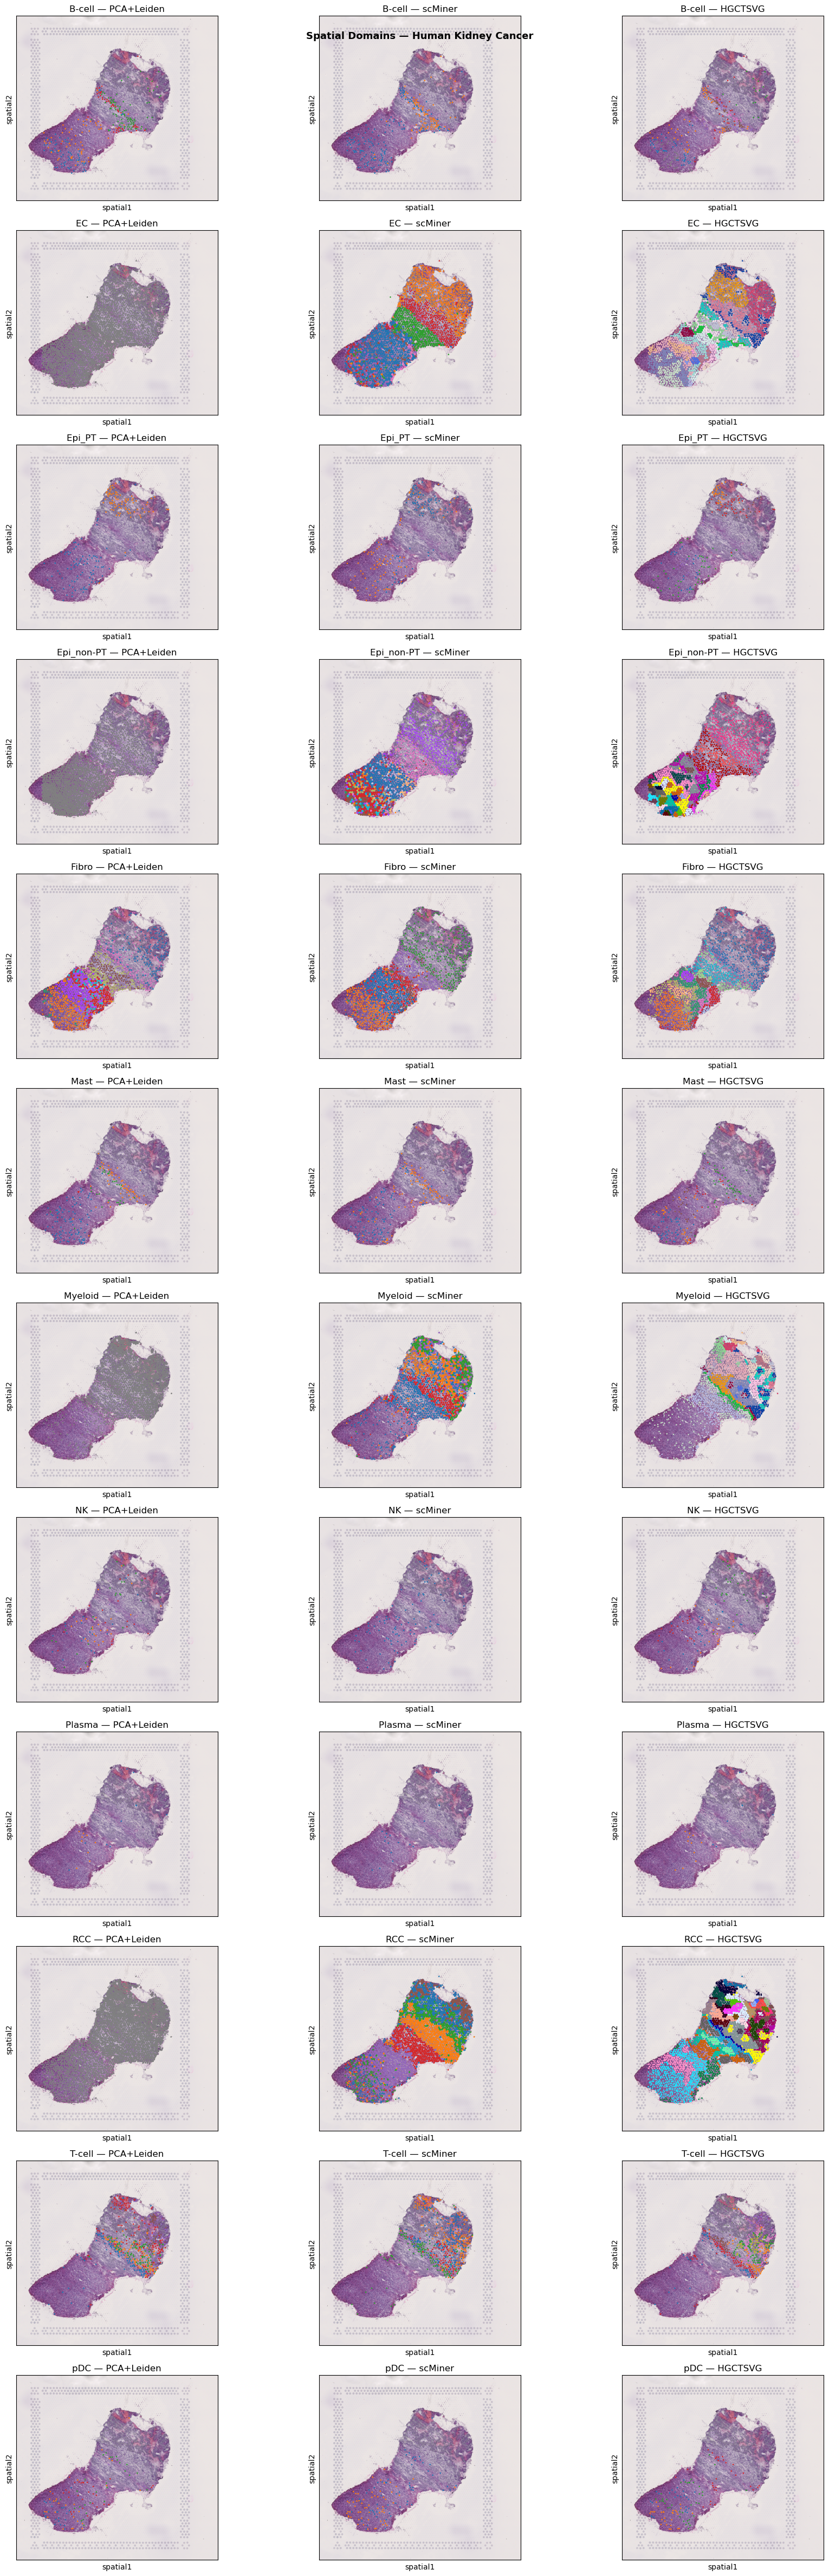

In [35]:
import squidpy as sq
import scanpy as sc
import pandas as pd
import re, numpy as np

scminer_dir = project_metadata.project_folder / 'scminer_clusters'
ct_list = project_metadata.ct_list
has_scminer = scminer_dir.exists()

fig, axes = plt.subplots(len(ct_list), 3, figsize=(18, 4 * len(ct_list)))
if len(ct_list) == 1: axes = axes[np.newaxis, :]
fig.suptitle('Spatial Domains — Human Kidney Cancer', fontsize=13, fontweight='bold')

for row, ct in enumerate(ct_list):
    adata_ct = load_ct_spatial_data(ct).copy()

    # --- PCA + Leiden ---
    ax = axes[row, 0]
    adata_pca = adata_ct.copy()
    n = max(1, min(50, adata_pca.n_obs - 1, adata_pca.n_vars - 1))
    sc.pp.pca(adata_pca, n_comps=n, mask_var=None)
    sc.pp.neighbors(adata_pca)
    sc.tl.leiden(adata_pca, flavor='igraph', n_iterations=2)
    adata_pca.obs['pca_domain'] = pd.Categorical(adata_pca.obs['leiden'])
    sq.pl.spatial_scatter(adata_pca, color='pca_domain', ax=ax,
                          title=f'{ct} — PCA+Leiden', legend_loc=None, size=1)

    # --- scMiner ---
    ax = axes[row, 1]
    safe = re.sub(r'[^A-Za-z0-9_]', '_', ct)
    sm_csv = scminer_dir / f'{safe}.csv'
    if sm_csv.exists():
        sm = pd.read_csv(sm_csv, dtype={'cell_id': str, 'cluster': str}).set_index('cell_id')
        common = adata_ct.obs_names.intersection(sm.index)
        adata_sm = adata_ct[common].copy()
        adata_sm.obs['sm_domain'] = pd.Categorical(sm.loc[common, 'cluster'].values)
        sq.pl.spatial_scatter(adata_sm, color='sm_domain', ax=ax,
                              title=f'{ct} — scMiner', legend_loc=None, size=1)
    else:
        ax.text(0.5, 0.5, 'pending', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{ct} — scMiner (pending)', fontsize=9)

    # --- HGCTSVG ---
    ax = axes[row, 2]
    run_csv = project_metadata.eval_dir / 'run_0' / f'clusters_ct_{ct}.csv'
    if run_csv.exists():
        hg = pd.read_csv(run_csv, index_col=0)
        hg_aligned = hg.reindex(adata_ct.obs_names.astype(int))
        adata_ct.obs['hg_domain'] = pd.Categorical(hg_aligned['domain'].astype(str).values)
        sq.pl.spatial_scatter(adata_ct, color='hg_domain', ax=ax,
                              title=f'{ct} — HGCTSVG', legend_loc=None, size=1)
    else:
        ax.text(0.5, 0.5, 'no clusters', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{ct} — HGCTSVG (pending)', fontsize=9)

plt.tight_layout()
plt.savefig('spatial_domains_comparison.png', dpi=120, bbox_inches='tight')
plt.show()